In [1]:
from keras.datasets import california_housing

I0000 00:00:1794909145.928741   19727 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794909146.417450   19727 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794909148.315341   19727 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
(train_data, train_targets), (test_data, test_targets) = california_housing.load_data(version="small")

743530/743530 ━━━━━━━━━━━━━━━━━━━━ 1s 2us/step


In [8]:
train_data.shape

(480, 8)

In [9]:
train_targets.shape

(480,)

In [10]:
test_data.shape

(120, 8)

In [11]:
test_targets.shape

(120,)

In [22]:
train_data.shape

(480, 8)

In [20]:
mean = train_data.mean(axis=0)
std = train_data.std(axis=0)
x_train = (train_data - mean) / std
x_test = (test_data - mean) / std

In [28]:
y_train = train_targets / 100000
y_test = test_targets / 100000

In [31]:
y_train.max()

np.float32(5.00001)

In [32]:
import keras
from keras import layers

def get_model():
    # Because you need to instantiate the same model multiple times,
    # you use a function to construct it.
    model = keras.Sequential(
        [
            layers.Dense(64, activation="relu"),
            layers.Dense(64, activation="relu"),
            layers.Dense(1),
        ]
    )
    model.compile(
        optimizer="adam",
        loss="mean_squared_error",
        metrics=["mean_absolute_error"],
    )
    return model

In [33]:
import numpy as np

In [34]:
k = 4
num_val_samples = len(x_train) // k
num_epochs = 50
all_scores = []
for i in range(k):
    print(f"Processing fold #{i + 1}")
    # Prepares the validation data: data from partition #k
    fold_x_val = x_train[i * num_val_samples : (i + 1) * num_val_samples]
    fold_y_val = y_train[i * num_val_samples : (i + 1) * num_val_samples]
    # Prepares the training data: data from all other partitions
    fold_x_train = np.concatenate(
        [x_train[: i * num_val_samples], x_train[(i + 1) * num_val_samples :]],
        axis=0,
    )
    fold_y_train = np.concatenate(
        [y_train[: i * num_val_samples], y_train[(i + 1) * num_val_samples :]],
        axis=0,
    )
    # Builds the Keras model (already compiled)
    model = get_model()
    # Trains the model
    model.fit(
        fold_x_train,
        fold_y_train,
        epochs=num_epochs,
        batch_size=16,
        verbose=0,
    )
    # Evaluates the model on the validation data
    scores = model.evaluate(fold_x_val, fold_y_val, verbose=0)
    val_loss, val_mae = scores
    all_scores.append(val_mae)

Processing fold #1


E0000 00:00:1794910607.547312   19727 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Processing fold #2
Processing fold #3
Processing fold #4


In [35]:
[round(value, 3) for value in all_scores]

[0.289, 0.319, 0.22, 0.331]

In [36]:
round(np.mean(all_scores), 3)

np.float64(0.29)

In [37]:
k = 4
num_val_samples = len(x_train) // k
num_epochs = 200
all_mae_histories = []
for i in range(k):
    print(f"Processing fold #{i + 1}")
    # Prepares the validation data: data from partition #k
    fold_x_val = x_train[i * num_val_samples : (i + 1) * num_val_samples]
    fold_y_val = y_train[i * num_val_samples : (i + 1) * num_val_samples]
    # Prepares the training data: data from all other partitions
    fold_x_train = np.concatenate(
        [x_train[: i * num_val_samples], x_train[(i + 1) * num_val_samples :]],
        axis=0,
    )
    fold_y_train = np.concatenate(
        [y_train[: i * num_val_samples], y_train[(i + 1) * num_val_samples :]],
        axis=0,
    )
    # Builds the Keras model (already compiled)
    model = get_model()
    # Trains the model
    history = model.fit(
        fold_x_train,
        fold_y_train,
        validation_data=(fold_x_val, fold_y_val),
        epochs=num_epochs,
        batch_size=16,
        verbose=0,
    )
    mae_history = history.history["val_mean_absolute_error"]
    all_mae_histories.append(mae_history)

Processing fold #1
Processing fold #2
Processing fold #3
Processing fold #4


In [38]:
average_mae_history = [
    np.mean([x[i] for x in all_mae_histories]) for i in range(num_epochs)
]

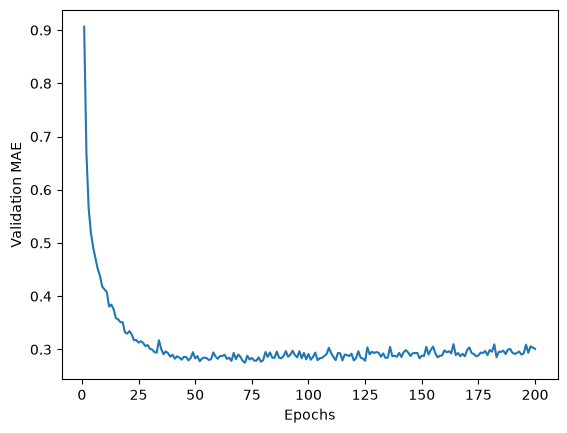

In [40]:
import matplotlib.pyplot as plt
epochs = range(1, len(average_mae_history) + 1)
plt.plot(epochs, average_mae_history)
plt.xlabel("Epochs")
plt.ylabel("Validation MAE")
plt.show()

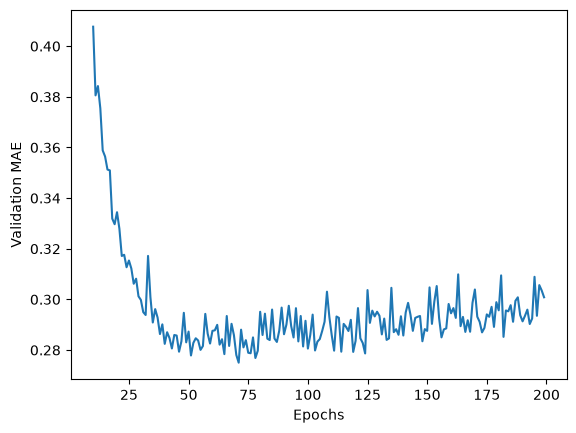

In [41]:
truncated_mae_history = average_mae_history[10:]
epochs = range(10, len(truncated_mae_history) + 10)
plt.plot(epochs, truncated_mae_history)
plt.xlabel("Epochs")
plt.ylabel("Validation MAE")
plt.show()

In [42]:
# Gets a fresh, compiled model
model = get_model()
# Trains it on the entirety of the data
model.fit(x_train, y_train, epochs=130, batch_size=16, verbose=0)
test_mean_squared_error, test_mean_absolute_error = model.evaluate(
    x_test, y_test
)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2986 - mean_absolute_error: 0.3179 


In [43]:
round(test_mean_absolute_error, 3)

0.318

In [48]:
predictions = model.predict(x_test)
predictions[0] * 100_000

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


array([287284.44], dtype=float32)

In [47]:
test_targets[0]

np.float32(218800.0)

In [49]:
287284.44 - 218800.0

68484.44